# MVP – Sistema de Suporte à Decisão para Manutenção Preditiva

## Contextualização

A manutenção preditiva utiliza dados operacionais de máquinas e equipamentos para identificar condições associadas à ocorrência de falhas. A utilização de técnicas de Machine Learning pode auxiliar gestores e equipes de manutenção na identificação de condições operacionais associadas à ocorrência de falhas que demandam maior atenção.

## Objetivo

Desenvolver um Mínimo Produto Viável (MVP) de um Sistema de Suporte à Decisão capaz de analisar condições operacionais de uma máquina e identificar situações associadas à ocorrência de falhas, auxiliando na priorização de inspeções e ações de manutenção.

O sistema será desenvolvido a partir do conjunto de dados **AI4I 2020 Predictive Maintenance Dataset**, disponibilizado pelo UCI Machine Learning Repository.

In [1]:
!pip install -q ucimlrepo

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)

In [3]:
# Carregamento do AI4I 2020 Predictive Maintenance Dataset
ai4i = fetch_ucirepo(id=601)

# Variáveis de entrada
X = ai4i.data.features.copy()

# Variável alvo escolhida para o MVP
y = ai4i.data.targets["Machine failure"].copy()

print("Dataset carregado com sucesso.")
print(f"Quantidade de registros: {len(X)}")
print(f"Quantidade de variáveis de entrada: {X.shape[1]}")

Dataset carregado com sucesso.
Quantidade de registros: 10000
Quantidade de variáveis de entrada: 6


In [4]:
X.head()

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


In [5]:
y.head()

,Machine failure
0,0
1,0
2,0
3,0
4,0


In [6]:
print("=== DIMENSÕES ===")
print("X:", X.shape)
print("y:", y.shape)

print("\n=== TIPOS DAS VARIÁVEIS ===")
print(X.dtypes)

print("\n=== VALORES AUSENTES ===")
print(X.isnull().sum())
print("Alvo:", y.isnull().sum())

print("\n=== DISTRIBUIÇÃO DO ALVO ===")
print(y.value_counts())
print("\nPercentual:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\n=== CATEGORIAS DE TYPE ===")
print(X["Type"].value_counts())

=== DIMENSÕES ===
X: (10000, 6)
y: (10000,)

=== TIPOS DAS VARIÁVEIS ===
Type                    object
Air temperature        float64
Process temperature    float64
Rotational speed         int64
Torque                 float64
Tool wear                int64
dtype: object

=== VALORES AUSENTES ===
Type                   0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
dtype: int64
Alvo: 0

=== DISTRIBUIÇÃO DO ALVO ===
Machine failure
0    9661
1     339
Name: count, dtype: int64

Percentual:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

=== CATEGORIAS DE TYPE ===
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


## Variáveis utilizadas

O modelo utilizará seis características operacionais como variáveis de entrada:

- **Type:** categoria de qualidade do produto (L, M ou H);
- **Air temperature:** temperatura do ar, em Kelvin;
- **Process temperature:** temperatura do processo, em Kelvin;
- **Rotational speed:** velocidade de rotação, em rpm;
- **Torque:** torque aplicado, em Nm;
- **Tool wear:** tempo de desgaste da ferramenta, em minutos.

A variável alvo será **Machine failure**, sendo:

- **0:** operação sem falha;
- **1:** ocorrência de falha.

As variáveis que identificam modos específicos de falha (TWF, HDF, PWF, OSF e RNF) não serão utilizadas como entradas do modelo, pois estão diretamente relacionadas à definição da variável alvo e poderiam causar vazamento de informação.

In [7]:
distribuicao = y.value_counts().sort_index()
percentual = y.value_counts(normalize=True).sort_index() * 100

resumo_classes = pd.DataFrame({
    "Quantidade": distribuicao,
    "Percentual (%)": percentual.round(2)
})

resumo_classes.index = ["Sem falha", "Com falha"]

resumo_classes

,Quantidade,Percentual (%)
Sem falha,9661,96.61
Com falha,339,3.39


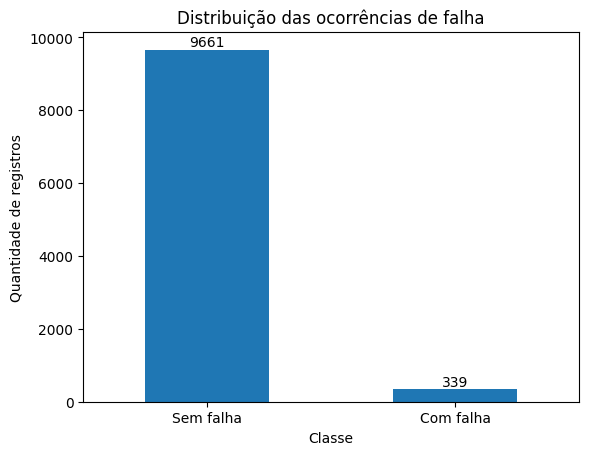

In [8]:
ax = resumo_classes["Quantidade"].plot(kind="bar")

plt.title("Distribuição das ocorrências de falha")
plt.ylabel("Quantidade de registros")
plt.xlabel("Classe")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container)

plt.show()

## Desbalanceamento das classes

Observa-se que a maior parte dos registros representa condições normais de funcionamento, enquanto as ocorrências de falha correspondem a uma pequena parcela da base.

Esse desbalanceamento é importante para a avaliação dos modelos. Um classificador que previsse apenas "sem falha" poderia apresentar alta acurácia, apesar de ser incapaz de identificar situações de falha.

Por esse motivo, além da acurácia, serão analisadas métricas como **precision, recall e F1-score**, com atenção especial à capacidade do modelo de identificar corretamente as ocorrências de falha.

In [9]:
# Separação dos dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("\nDistribuição das classes no conjunto de teste:")
print(y_test.value_counts())

Treino: (8000, 6)
Teste: (2000, 6)

Distribuição das classes no conjunto de teste:
Machine failure
0    1932
1      68
Name: count, dtype: int64


## Preparação dos dados

Antes do treinamento dos modelos, os dados serão preparados de acordo com o tipo de variável. A variável categórica **Type** será transformada em representação numérica, enquanto as variáveis numéricas serão padronizadas para utilização na Regressão Logística.

Para o Random Forest, a variável **Type** também será codificada, mas não será necessária a padronização das variáveis numéricas.

In [10]:
# Definição das variáveis categóricas e numéricas
variaveis_categoricas = ["Type"]

variaveis_numericas = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

# Pré-processamento para a Regressão Logística
preprocessador_logistica = ColumnTransformer(
    transformers=[
        (
            "categorica",
            OneHotEncoder(handle_unknown="ignore"),
            variaveis_categoricas
        ),
        (
            "numerica",
            StandardScaler(),
            variaveis_numericas
        )
    ]
)

# Pré-processamento para o Random Forest
preprocessador_rf = ColumnTransformer(
    transformers=[
        (
            "categorica",
            OneHotEncoder(handle_unknown="ignore"),
            variaveis_categoricas
        )
    ],
    remainder="passthrough"
)

print("Pré-processamento definido com sucesso.")

Pré-processamento definido com sucesso.


## Modelo 1 — Regressão Logística

A Regressão Logística será utilizada como modelo inicial de referência. O objetivo é verificar sua capacidade de classificar as condições operacionais entre **sem falha** e **com falha**.


In [11]:
# Pipeline da Regressão Logística
modelo_logistica = Pipeline(
    steps=[
        ("preprocessamento", preprocessador_logistica),
        ("modelo", LogisticRegression(max_iter=1000, random_state=42))
    ]
)

# Treinamento do modelo
modelo_logistica.fit(X_train, y_train)

# Previsões no conjunto de teste
y_pred_logistica = modelo_logistica.predict(X_test)

print("Regressão Logística treinada com sucesso.")

Regressão Logística treinada com sucesso.


=== REGRESSÃO LOGÍSTICA ===
              precision    recall  f1-score   support

   Sem falha       0.97      1.00      0.98      1932
   Com falha       0.64      0.10      0.18        68

    accuracy                           0.97      2000
   macro avg       0.80      0.55      0.58      2000
weighted avg       0.96      0.97      0.96      2000



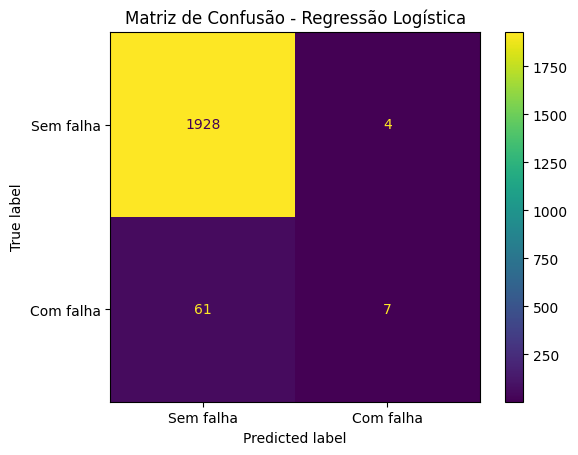

In [12]:
print("=== REGRESSÃO LOGÍSTICA ===")

print(
    classification_report(
        y_test,
        y_pred_logistica,
        target_names=["Sem falha", "Com falha"],
        zero_division=0
    )
)

matriz_logistica = confusion_matrix(y_test, y_pred_logistica)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_logistica,
    display_labels=["Sem falha", "Com falha"]
)

disp.plot()
plt.title("Matriz de Confusão - Regressão Logística")
plt.show()

### Resultado da Regressão Logística

Apesar de apresentar acurácia elevada, a Regressão Logística demonstrou baixa capacidade de identificar ocorrências de falha. Das 68 falhas presentes no conjunto de teste, apenas 7 foram corretamente identificadas, resultando em recall de 0,10 para a classe "Com falha".

Esse resultado evidencia o impacto do desbalanceamento das classes e reforça a necessidade de analisar métricas específicas da classe de falha, e não apenas a acurácia geral do modelo.




---



## Modelo 2 — Random Forest

O Random Forest será utilizado como segundo modelo de classificação. Por combinar múltiplas árvores de decisão, o algoritmo é capaz de representar relações não lineares entre as condições operacionais da máquina e a ocorrência de falhas.


In [13]:
# Pipeline do Random Forest
modelo_rf = Pipeline(
    steps=[
        ("preprocessamento", preprocessador_rf),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

# Treinamento do modelo
modelo_rf.fit(X_train, y_train)

# Previsões no conjunto de teste
y_pred_rf = modelo_rf.predict(X_test)

print("Random Forest treinado com sucesso.")

Random Forest treinado com sucesso.


=== RANDOM FOREST ===
              precision    recall  f1-score   support

   Sem falha       0.98      1.00      0.99      1932
   Com falha       0.90      0.53      0.67        68

    accuracy                           0.98      2000
   macro avg       0.94      0.76      0.83      2000
weighted avg       0.98      0.98      0.98      2000



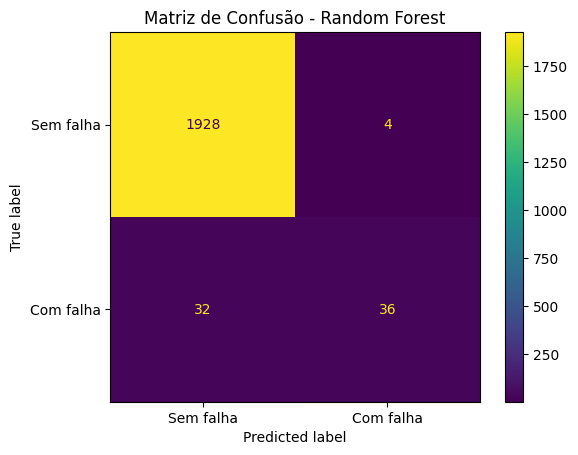

In [14]:
print("=== RANDOM FOREST ===")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Sem falha", "Com falha"],
        zero_division=0
    )
)

matriz_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=["Sem falha", "Com falha"]
)

disp.plot()
plt.title("Matriz de Confusão - Random Forest")
plt.show()

### Resultado do Random Forest

O Random Forest apresentou desempenho superior à Regressão Logística na identificação das falhas. Das 68 ocorrências de falha presentes no conjunto de teste, 36 foram corretamente identificadas, resultando em recall de 0,53 e F1-score de 0,67 para a classe "Com falha".

Apesar da melhora significativa, o modelo ainda deixou de identificar 32 das 68 falhas reais. Considerando o contexto de manutenção preditiva, será realizado um ajuste para reduzir o impacto do desbalanceamento das classes.



## Ajuste do Random Forest para o desbalanceamento

Como as ocorrências de falha representam uma parcela pequena da base, será testado um Random Forest com pesos balanceados entre as classes. O objetivo é aumentar a capacidade de identificação das falhas sem modificar artificialmente os dados disponíveis.

In [15]:
# Random Forest com balanceamento das classes
modelo_rf_balanceado = Pipeline(
    steps=[
        ("preprocessamento", preprocessador_rf),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=100,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

# Treinamento
modelo_rf_balanceado.fit(X_train, y_train)

# Previsões
y_pred_rf_balanceado = modelo_rf_balanceado.predict(X_test)

print("Random Forest balanceado treinado com sucesso.")

Random Forest balanceado treinado com sucesso.


=== RANDOM FOREST BALANCEADO ===
              precision    recall  f1-score   support

   Sem falha       0.98      1.00      0.99      1932
   Com falha       0.97      0.46      0.62        68

    accuracy                           0.98      2000
   macro avg       0.97      0.73      0.81      2000
weighted avg       0.98      0.98      0.98      2000



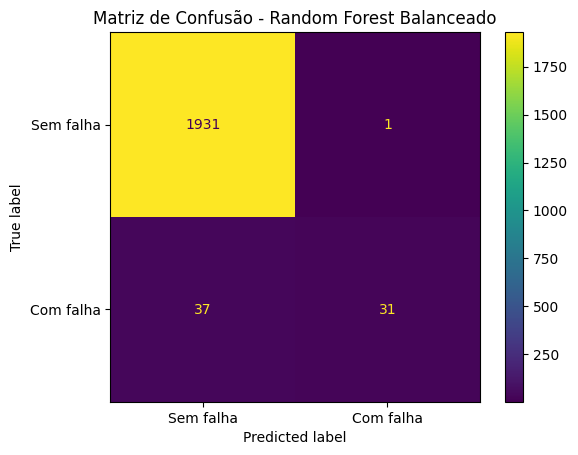

In [16]:
print("=== RANDOM FOREST BALANCEADO ===")

print(
    classification_report(
        y_test,
        y_pred_rf_balanceado,
        target_names=["Sem falha", "Com falha"],
        zero_division=0
    )
)

matriz_rf_balanceado = confusion_matrix(
    y_test,
    y_pred_rf_balanceado
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf_balanceado,
    display_labels=["Sem falha", "Com falha"]
)

disp.plot()
plt.title("Matriz de Confusão - Random Forest Balanceado")
plt.show()

### Resultado do ajuste de balanceamento

O Random Forest com pesos balanceados apresentou precisão elevada para a classe de falha, porém reduziu sua capacidade de identificar as falhas reais. O recall da classe "Com falha" caiu de 0,53 para 0,46 e o F1-score de 0,67 para 0,62.

Dessa forma, o Random Forest original apresentou o melhor equilíbrio entre identificação das falhas e precisão das previsões entre os modelos avaliados.

In [17]:
resultados = pd.DataFrame({
    "Modelo": [
        "Regressão Logística",
        "Random Forest",
        "Random Forest Balanceado"
    ],
    "Acurácia": [
        accuracy_score(y_test, y_pred_logistica),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_balanceado)
    ],
    "Precisão - Falha": [
        precision_score(y_test, y_pred_logistica, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0),
        precision_score(y_test, y_pred_rf_balanceado, zero_division=0)
    ],
    "Recall - Falha": [
        recall_score(y_test, y_pred_logistica, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_rf_balanceado, zero_division=0)
    ],
    "F1-score - Falha": [
        f1_score(y_test, y_pred_logistica, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_rf_balanceado, zero_division=0)
    ]
})

resultados.round(3)

,Modelo,Acurácia,Precisão - Falha,Recall - Falha,F1-score - Falha
0,Regressão Logística,0.968,0.636,0.103,0.177
1,Random Forest,0.982,0.900,0.529,0.667
2,Random Forest Balanceado,0.981,0.969,0.456,0.620


## Seleção do modelo

Entre os modelos avaliados, o **Random Forest original** apresentou o melhor desempenho para a identificação de falhas, alcançando recall de 0,529 e F1-score de 0,667 para a classe "Com falha".

Embora o Random Forest balanceado tenha apresentado maior precisão, sua capacidade de identificar falhas foi inferior. Dessa forma, o Random Forest original foi selecionado para compor o Sistema de Suporte à Decisão.

## MVP — Sistema de Suporte à Decisão

Os exemplos apresentados a seguir utilizam registros do conjunto de teste apenas para demonstrar o funcionamento do MVP. O desempenho global do modelo é representado pelas métricas apresentadas anteriormente.

A função abaixo representa o MVP do sistema. O usuário informa as condições operacionais da máquina e o modelo selecionado realiza a classificação.

A saída do sistema não substitui a decisão do responsável pela manutenção. Ela funciona como informação adicional para auxiliar na priorização de inspeções e ações de manutenção.

In [18]:
def avaliar_maquina(
    tipo,
    temperatura_ar,
    temperatura_processo,
    velocidade_rotacao,
    torque,
    desgaste_ferramenta
):
    # Criação do registro da máquina
    dados_maquina = pd.DataFrame({
        "Type": [tipo],
        "Air temperature": [temperatura_ar],
        "Process temperature": [temperatura_processo],
        "Rotational speed": [velocidade_rotacao],
        "Torque": [torque],
        "Tool wear": [desgaste_ferramenta]
    })

    # Previsão realizada pelo Random Forest selecionado
    previsao = modelo_rf.predict(dados_maquina)[0]

    # Score atribuído pelo modelo à classe de falha
    score_falha = modelo_rf.predict_proba(dados_maquina)[0][1]

    print("=== SISTEMA DE SUPORTE À DECISÃO ===")
    print(f"Score de falha do modelo: {score_falha:.2%}")

    if previsao == 1:
        print("Resultado: POSSÍVEL FALHA IDENTIFICADA")
        print("Recomendação: priorizar a avaliação desta condição pela equipe de manutenção.")
    else:
        print("Resultado: NÃO FOI IDENTIFICADA FALHA")
        print("Recomendação: manter o acompanhamento das condições operacionais.")

In [19]:
# Reúne as condições das máquinas de teste com o resultado real e a previsão
resultados_teste = X_test.copy()

resultados_teste["Falha real"] = y_test.values
resultados_teste["Falha prevista"] = y_pred_rf

# Seleciona um caso em que houve falha e o modelo identificou corretamente
caso_falha = resultados_teste[
    (resultados_teste["Falha real"] == 1) &
    (resultados_teste["Falha prevista"] == 1)
].head(1)

caso_falha

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Falha real,Falha prevista
1391,L,298.9,310.2,2737,8.8,142,1,1


In [20]:
avaliar_maquina(
    tipo="L",
    temperatura_ar=298.9,
    temperatura_processo=310.2,
    velocidade_rotacao=2737,
    torque=8.8,
    desgaste_ferramenta=142
)

=== SISTEMA DE SUPORTE À DECISÃO ===
Score de falha do modelo: 94.00%
Resultado: POSSÍVEL FALHA IDENTIFICADA
Recomendação: priorizar a avaliação desta condição pela equipe de manutenção.


In [21]:
# Seleciona um caso em que não houve falha e o modelo identificou corretamente
caso_sem_falha = resultados_teste[
    (resultados_teste["Falha real"] == 0) &
    (resultados_teste["Falha prevista"] == 0)
].head(1)

caso_sem_falha

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Falha real,Falha prevista
2997,L,300.5,309.8,1345,62.7,153,0,0


In [22]:
avaliar_maquina(
    tipo="L",
    temperatura_ar=300.5,
    temperatura_processo=309.8,
    velocidade_rotacao=1345,
    torque=62.7,
    desgaste_ferramenta=153
)

=== SISTEMA DE SUPORTE À DECISÃO ===
Score de falha do modelo: 13.00%
Resultado: NÃO FOI IDENTIFICADA FALHA
Recomendação: manter o acompanhamento das condições operacionais.


## Conclusão

O MVP desenvolvido demonstrou a aplicação de técnicas de Machine Learning em um Sistema de Suporte à Decisão voltado à manutenção preditiva.

Foram avaliados três modelos: Regressão Logística, Random Forest e Random Forest com balanceamento de classes. Entre eles, o **Random Forest original apresentou o melhor desempenho para a identificação de falhas**, com acurácia de 0,982, precisão de 0,900, recall de 0,529 e F1-score de 0,667 para a classe "Com falha".

O sistema desenvolvido permite inserir condições operacionais de uma máquina e obter uma classificação acompanhada de uma recomendação para apoio à equipe de manutenção. Dessa forma, o modelo pode auxiliar na priorização de inspeções e ações de manutenção, sem substituir a decisão do responsável.

Como limitação, o modelo ainda não identifica todas as ocorrências de falha, apresentando recall de 0,529. Portanto, este MVP representa uma solução inicial, que poderá ser aprimorada com novas técnicas de modelagem, ajustes de parâmetros e estratégias específicas para o desbalanceamento dos dados.